# Performance benchmark: Vo centre finding on I12 dataset 1

Measure ten GPU centre searches on the central sinogram of I12 dataset 1
after dark/flat correction. Exclude loading, preprocessing and plotting
from the timing, and report individually synchronised measurements.

## Data and execution

Use the named dataset archives from [Zenodo record 17252190](https://zenodo.org/records/17252190).
The repository downloader verifies the archive checksums.
Run from the repository root:

```bash
python .scripts/download_zenodo.py Zenodo
python -m pip install -e '.[validation]'
python -m pytest --nbmake --nbmake-timeout=1800 --overwrite docs/source/benchmarks/center_vo_i12_dataset1.ipynb
```

Use an NVIDIA GPU with compatible CuPy and ToMoBAR installed, plus ASTRA for
ASTRA-based reconstruction. Run notebooks serially. Set `HTTOMOLIBGPU_DATA_DIR`
to use an archive stored elsewhere.

Documentation builds render saved outputs without running GPU computations.
Execute with `--overwrite` before building documentation to update the results.


In [1]:
import gc
import hashlib
import json
import os
import platform
from importlib.metadata import version
from pathlib import Path

import cupy as cp
import matplotlib.pyplot as plt
import numpy as np

from httomolibgpu.prep.normalize import dark_flat_field_correction, minus_log
from httomolibgpu.recon.rotation import find_center_vo, find_center_pc, find_center_360

repo_root = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "pyproject.toml").is_file() and (p / "httomolibgpu").is_dir()
    ),
    None,
)
configured_dir = os.environ.get("HTTOMOLIBGPU_DATA_DIR")
if configured_dir:
    data_dir = Path(configured_dir).expanduser()
elif repo_root is not None:
    data_dir = repo_root / "Zenodo"
else:
    raise FileNotFoundError("Set HTTOMOLIBGPU_DATA_DIR to the Zenodo archive directory")

props = cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)
environment = {
    "python": platform.python_version(),
    "packages": {
        name: version(name) for name in ("httomolibgpu", "numpy", "matplotlib")
    },
    "cupy": cp.__version__,
    "cuda_runtime": cp.cuda.runtime.runtimeGetVersion(),
    "cuda_driver": cp.cuda.runtime.driverGetVersion(),
    "gpu": (
        props["name"].decode() if isinstance(props["name"], bytes) else props["name"]
    ),
}
print(json.dumps(environment, indent=2))
results = []
dataset_provenance = {}


def clean_memory():
    gc.collect()
    cp.get_default_memory_pool().free_all_blocks()
    cp.get_default_pinned_memory_pool().free_all_blocks()


def archive_path(name):
    path = data_dir / (name + ".npz")
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {path}; run .scripts/download_zenodo.py first"
        )
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    dataset_provenance[name] = {
        "archive": path.name,
        "sha256": digest.hexdigest(),
        "zenodo_record": "17252190",
    }
    print(json.dumps(dataset_provenance[name], indent=2))
    return path


def load_transmission(name):
    with np.load(archive_path(name)) as archive:
        raw = cp.asarray(archive["projdata"])
        flats = cp.asarray(archive["flats"])
        darks = cp.asarray(archive["darks"])
        print("Raw, flats, darks:", raw.shape, flats.shape, darks.shape)
    transmission = dark_flat_field_correction(raw, flats, darks)
    del raw, flats, darks
    clean_memory()
    return transmission


def display_sinogram(sinogram, observed, expected, title):
    image = cp.asnumpy(sinogram)
    lo, hi = np.percentile(image[np.isfinite(image)], [1, 99])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    im = axes[0].imshow(image, cmap="gray", aspect="auto", vmin=lo, vmax=hi)
    axes[0].axvline(float(observed), color="tab:orange", label="Observed centre")
    axes[0].axvline(
        float(expected), color="tab:cyan", linestyle="--", label="Reference centre"
    )
    axes[0].set(
        title=title, xlabel="Detector column (pixel)", ylabel="Projection index"
    )
    axes[0].legend(fontsize=8)
    fig.colorbar(im, ax=axes[0], label="Corrected transmission")
    axes[1].plot(np.mean(image, axis=0))
    axes[1].axvline(float(observed), color="tab:orange")
    axes[1].axvline(float(expected), color="tab:cyan", linestyle="--")
    axes[1].set(
        title="Angular mean profile",
        xlabel="Detector column (pixel)",
        ylabel="Mean transmission",
    )
    plt.show()
    plt.close(fig)


def check_results():
    print(json.dumps(results, indent=2))
    failed = [row for row in results if not row["passed"]]
    assert not failed, "Rotation validation checks failed: " + json.dumps(
        failed, indent=2
    )
    print(f"All {len(results)} rotation validation checks passed.")

{
  "python": "3.14.7",
  "packages": {
    "httomolibgpu": "6.0.1.post16+git.bbaa03d2.dirty",
    "numpy": "2.4.6",
    "matplotlib": "3.11.1"
  },
  "cupy": "14.2.0",
  "cuda_runtime": 13020,
  "cuda_driver": 13020,
  "gpu": "NVIDIA GeForce RTX 4060"
}


## Preprocessing and timing protocol

Apply dark/flat correction and copy the central sinogram into contiguous GPU
storage before timing. Search with `smin=-100`, `smax=100` and `step=0.25`.
Use one untimed warm-up and ten measured calls with the same parameters.
Synchronise before and after each call; exclude NVTX range setup and cleanup.
Check the warm-up centre and dtype, and require finite, positive timings.


{
  "archive": "i12_dataset1.npz",
  "sha256": "1ebf3ffd3686213fb189681ba721acc0f19e12d3432ed4fbcab4e3bb3064927b",
  "zenodo_record": "17252190"
}


Raw, flats, darks: (1801, 50, 2560) (50, 50, 2560) (20, 50, 2560)


Warm-up centre: 1253.75 parameters: {'smin': -100, 'smax': 100, 'step': 0.25}


{
  "units": "ms",
  "repeats": 10,
  "mean": 481.55177249999997,
  "median": 477.4388775,
  "std_sample": 8.66992177420278,
  "minimum": 475.378939,
  "maximum": 501.169099,
  "individual_runs": [
    478.3619,
    477.331142,
    476.260991,
    475.378939,
    482.958778,
    501.169099,
    493.071333,
    477.001874,
    477.546613,
    476.437056
  ]
}


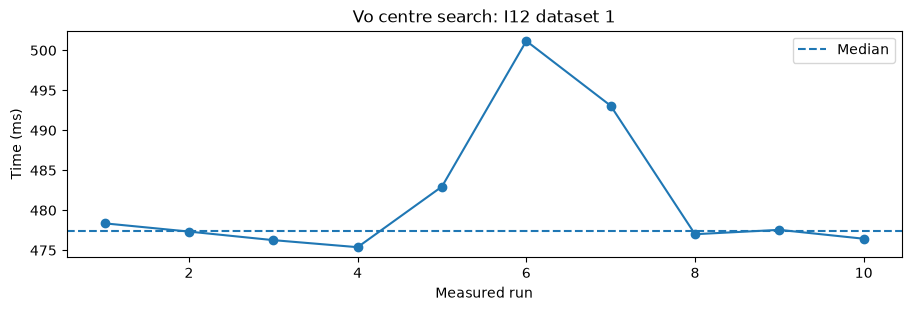

In [2]:
import time
from cupy.cuda import nvtx

data = load_transmission("i12_dataset1")
mid_row = data.shape[1] // 2
sinogram = cp.ascontiguousarray(data[:, mid_row, :])
del data
clean_memory()
parameters = {"smin": -100, "smax": 100, "step": 0.25}
repeats = 10
device = cp.cuda.Device()
cor = find_center_vo(sinogram, **parameters)
device.synchronize()
assert cor == 1253.75
assert cor.dtype == np.float32
print("Warm-up centre:", float(cor), "parameters:", parameters)

timings_ms = []
centres = []
for iteration in range(repeats):
    device.synchronize()
    nvtx.RangePush("Vo centre search")
    try:
        start = time.perf_counter_ns()
        cor = find_center_vo(sinogram, **parameters)
        device.synchronize()
        timings_ms.append((time.perf_counter_ns() - start) / 1e6)
    finally:
        nvtx.RangePop()
    centres.append(float(cor))

timings_ms = np.asarray(timings_ms)
assert np.isfinite(timings_ms).all() and (timings_ms > 0).all()
assert np.all(np.asarray(centres) == 1253.75)
summary = {
    "units": "ms",
    "repeats": repeats,
    "mean": float(timings_ms.mean()),
    "median": float(np.median(timings_ms)),
    "std_sample": float(timings_ms.std(ddof=1)),
    "minimum": float(timings_ms.min()),
    "maximum": float(timings_ms.max()),
    "individual_runs": timings_ms.tolist(),
}
print(json.dumps(summary, indent=2))
fig, ax = plt.subplots(figsize=(9, 3), constrained_layout=True)
ax.plot(np.arange(1, repeats + 1), timings_ms, "o-")
ax.axhline(np.median(timings_ms), linestyle="--", label="Median")
ax.set(
    title="Vo centre search: I12 dataset 1", xlabel="Measured run", ylabel="Time (ms)"
)
ax.legend()
plt.show()
plt.close(fig)
del sinogram
clean_memory()

## Interpretation

Compare timings only for the same dataset, search settings, software, hardware
and synchronisation protocol, on an otherwise idle GPU. This benchmark supplements
the multi-dataset numerical validation; it does not replace it.
